# CaloDiffusion — Pion Final Three Investigations

**Purpose:** investigate the three remaining pion anomalies using the three saved fidelity runs. This notebook does **not** train the model or generate new showers.

It focuses on:

1. **High-response event:** the 32.768 GeV shower with response about 1.598 and a 46.76 GeV deposit in native cell 523.
2. **Low-response event:** the 65.536 GeV shower with response about 0.00714.
3. **Extreme radial event:** the 8.192 GeV shower with radial RMS about 996.55 XML units.

It also checks the three-run compatibility, verifies the pion native-cell map from each run's saved geometry, compares selected showers with the fixed reference and scale-only samples, and exports tables and plots.

> **Important:** Cell-removal tests in this notebook are diagnostic sensitivity checks only. Never remove these showers or cells from the primary fidelity sample. A statistical outlier is not automatically a physically impossible shower.

## 0. Inputs and study conventions

Upload the three pion fidelity ZIP files from seeds `20260110`, `20260111`, and `20260112`. The notebook applies the established **10 MeV = 0.01 GeV** analysis cutoff to the saved native arrays. It does not change the model ECUT.

In [ ]:
import io, json, zipfile, hashlib, re, os, textwrap
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ENERGIES = (8.192, 32.768, 65.536)
EXPECTED_SEEDS = (20260110, 20260111, 20260112)
ANALYSIS_CUT_GEV = 0.01
EXPECTED_NATIVE_CELLS = 533

OUTPUT_DIR = Path("/content/pion_final_three_investigations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Energies:", ENERGIES)
print("Analysis cutoff:", ANALYSIS_CUT_GEV, "GeV (10 MeV)")
print("Expected native cells:", EXPECTED_NATIVE_CELLS)

Energies: (8.192, 32.768, 65.536)
Analysis cutoff: 0.01 GeV (10 MeV)
Expected native cells: 533


## 1. Upload the three fidelity ZIP files

In [ ]:
from google.colab import files
uploaded = files.upload()

zip_inputs = {
    name: payload
    for name, payload in uploaded.items()
    if name.lower().endswith(".zip")
}

if len(zip_inputs) != 3:
    raise ValueError(
        f"Expected exactly 3 fidelity ZIP files; received {len(zip_inputs)}. "
        "Upload the files for seeds 20260110, 20260111 and 20260112."
    )

print("Uploaded files:")
for name in zip_inputs:
    print(" -", name)

Saving validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip to validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip to validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip to validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip
Uploaded files:
 - validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip
 - validated_calo_controlled_pion_partition20261120_generation

## 2. Read manifests and verify run compatibility

We check that the reference file, checkpoint, partition, scale-only donors, repository revision and analysis cutoff are identical across all three runs. This is a necessary reproducibility check before comparing physics results.

In [ ]:
def find_member(zf, suffix):
    matches = [n for n in zf.namelist() if n.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one ZIP member ending with {suffix!r}; "
            f"found {len(matches)}: {matches[:5]}"
        )
    return matches[0]

runs = {}
for filename, payload in zip_inputs.items():
    zf = zipfile.ZipFile(io.BytesIO(payload))
    manifest_path = find_member(zf, "manifest.json")
    geometry_path = find_member(zf, "pion_geometry.json")
    manifest = json.loads(zf.read(manifest_path))
    geometry = json.loads(zf.read(geometry_path))

    seed = int(manifest["seed_streams"]["generation_seed"])
    if seed in runs:
        raise ValueError(f"Duplicate generation seed: {seed}")

    runs[seed] = {
        "filename": filename,
        "zip": zf,
        "manifest": manifest,
        "geometry": geometry,
    }

if tuple(sorted(runs)) != EXPECTED_SEEDS:
    raise ValueError(
        f"Expected generation seeds {EXPECTED_SEEDS}; found {tuple(sorted(runs))}"
    )

print("Loaded generation seeds:", sorted(runs))

# Compare the important manifest fields against the first run.
base_seed = EXPECTED_SEEDS[0]
base = runs[base_seed]["manifest"]
compat_rows = []

for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    fields = {
        "reference_hash_match": (
            m["reference_files"]["pion"]["sha256"]
            == base["reference_files"]["pion"]["sha256"]
        ),
        "checkpoint_hash_match": (
            m["checkpoints"]["pion"]["sha256"]
            == base["checkpoints"]["pion"]["sha256"]
        ),
        "partition_hash_match": (
            m["partition_sha256"]["pion"]
            == base["partition_sha256"]["pion"]
        ),
        "donor_hashes_match": (
            m["scale_donor_sha256"]["pion"]
            == base["scale_donor_sha256"]["pion"]
        ),
        "repository_revision_match": m["revision"] == base["revision"],
        "cutoff_match": (
            float(m["analysis_cut_GeV_overrides"]["pion"])
            == ANALYSIS_CUT_GEV
        ),
        "all_technical_gates_passed": bool(
            all(
                gate.get("passed", False)
                for gate in json.loads(runs[seed]["zip"].read(
                    find_member(runs[seed]["zip"], "validation_gates.json")
                ))
            )
        ),
        "reference_unseen_by_checkpoint": bool(
            m.get("reference_is_unseen_by_checkpoint", False)
        ),
    }
    compat_rows.append({"generation_seed": seed, **fields})

compatibility = pd.DataFrame(compat_rows)
display(compatibility)

must_match = [
    "reference_hash_match", "checkpoint_hash_match", "partition_hash_match",
    "donor_hashes_match", "repository_revision_match", "cutoff_match",
    "all_technical_gates_passed"
]
if not compatibility[must_match].all().all():
    raise RuntimeError(
        "Run compatibility check failed. Stop and inspect the table before interpreting results."
    )

# The embedded geometry metadata must also be identical across runs.
for seed in EXPECTED_SEEDS[1:]:
    if runs[seed]["geometry"] != runs[base_seed]["geometry"]:
        raise RuntimeError(f"Pion geometry metadata differs in seed {seed}.")

print("PASS: the three runs are compatible for this diagnostic comparison.")
print("PASS: saved pion geometry metadata is identical across runs.")
print("Reference/checkpoint independence:",
      "verified" if compatibility["reference_unseen_by_checkpoint"].all()
      else "NOT ESTABLISHED — retain this limitation in the report.")

compatibility.to_csv(OUTPUT_DIR / "run_compatibility.csv", index=False)

Loaded generation seeds: [20260110, 20260111, 20260112]


,generation_seed,reference_hash_match,checkpoint_hash_match,partition_hash_match,donor_hashes_match,repository_revision_match,cutoff_match,all_technical_gates_passed,reference_unseen_by_checkpoint
0,20260110,True,True,True,True,True,True,True,False
1,20260111,True,True,True,True,True,True,True,False
2,20260112,True,True,True,True,True,True,True,False


PASS: the three runs are compatible for this diagnostic comparison.
PASS: saved pion geometry metadata is identical across runs.
Reference/checkpoint independence: NOT ESTABLISHED — retain this limitation in the report.


## 3. Reconstruct and verify the 533-cell native geometry

The pion geometry has seven active layers with different radial and angular bin counts. We rebuild the cell-index map from the saved `pion_geometry.json` and confirm that it contains exactly 533 cells. This does not replace the earlier source-level native ordering verification; it confirms the geometry metadata bundled with these fidelity runs.

In [ ]:
geometry = runs[base_seed]["geometry"]
layer_ids = list(map(int, geometry["layer_ids"]))
n_angles = list(map(int, geometry["n_angles"]))
radial_edges = geometry["radial_edges"]

cell_rows = []
layer_rows = []
offset = 0

for ordinal, (layer_id, n_ang, edges_raw) in enumerate(
    zip(layer_ids, n_angles, radial_edges)
):
    edges = np.asarray(edges_raw, dtype=float)
    n_rad = len(edges) - 1
    start = offset
    stop = start + n_ang * n_rad

    layer_rows.append({
        "layer_ordinal": ordinal,
        "layer_id": layer_id,
        "n_angles": n_ang,
        "n_radial": n_rad,
        "native_start": start,
        "native_stop_exclusive": stop,
    })

    for angle in range(n_ang):
        for radial in range(n_rad):
            idx = start + angle * n_rad + radial
            cell_rows.append({
                "native_index": idx,
                "layer_ordinal": ordinal,
                "layer_id": layer_id,
                "angle_index": angle,
                "radial_bin": radial,
                "r_low_XML": edges[radial],
                "r_high_XML": edges[radial + 1],
                "r_center_XML": 0.5 * (edges[radial] + edges[radial + 1]),
            })
    offset = stop

cell_map = pd.DataFrame(cell_rows)
layer_map = pd.DataFrame(layer_rows)

assert len(cell_map) == EXPECTED_NATIVE_CELLS, len(cell_map)
assert offset == EXPECTED_NATIVE_CELLS
assert cell_map["native_index"].tolist() == list(range(EXPECTED_NATIVE_CELLS))

print("Native cell count:", len(cell_map))
print("Active layers:", len(layer_map))
display(layer_map)

# Verify the important cell mentioned in the closeout investigation.
cell523 = cell_map.loc[cell_map.native_index == 523].iloc[0]
print("\nNative cell 523 mapping:")
display(cell523.to_frame("value"))
assert int(cell523.layer_id) == 14
assert int(cell523.layer_ordinal) == 6
assert int(cell523.angle_index) == 0
assert int(cell523.radial_bin) == 0
assert np.isclose(cell523.r_low_XML, 0.0)
assert np.isclose(cell523.r_high_XML, 50.0)

print("PASS: cell 523 is layer ID 14, angle 0, radial bin 0 (0–50 XML units).")
cell_map.to_csv(OUTPUT_DIR / "pion_native_cell_map.csv", index=False)

Native cell count: 533
Active layers: 7


,layer_ordinal,layer_id,n_angles,n_radial,native_start,native_stop_exclusive
0,0,0,1,8,0,8
1,1,1,10,10,8,108
2,2,2,10,10,108,208
3,3,3,1,5,208,213
4,4,12,10,15,213,363
5,5,13,10,16,363,523
6,6,14,1,10,523,533



Native cell 523 mapping:


,value
native_index,523.0
layer_ordinal,6.0
layer_id,14.0
angle_index,0.0
radial_bin,0.0
r_low_XML,0.0
r_high_XML,50.0
r_center_XML,25.0


PASS: cell 523 is layer ID 14, angle 0, radial bin 0 (0–50 XML units).


## 4. Load saved reference, generator and scale-only native arrays

Each run ZIP contains the saved `native` arrays. We load all three energies and both generation repeats for all seeds. No model call is made.

In [ ]:
def load_npz_member(zf, suffix):
    member = find_member(zf, suffix)
    with np.load(io.BytesIO(zf.read(member)), allow_pickle=False) as npz:
        return {key: npz[key].copy() for key in npz.files}

DATA = {}
for seed in EXPECTED_SEEDS:
    zf = runs[seed]["zip"]
    DATA[seed] = {}
    for energy in ENERGIES:
        stem = f"arrays/pion_{energy:.3f}GeV_"
        DATA[seed][energy] = {
            "reference": load_npz_member(zf, stem + "reference_run-1.npz"),
            "generator_run0": load_npz_member(zf, stem + "generator_run0.npz"),
            "generator_run1": load_npz_member(zf, stem + "generator_run1.npz"),
            "scale_only": load_npz_member(zf, stem + "scale_only_run-1.npz"),
        }

# Basic shape and event-ID checks.
shape_rows = []
for seed in EXPECTED_SEEDS:
    for energy in ENERGIES:
        for method, obj in DATA[seed][energy].items():
            native = obj["native"]
            assert native.ndim == 2 and native.shape[1] == EXPECTED_NATIVE_CELLS
            assert len(obj["energy"]) == len(native)
            assert len(obj["event_id"]) == len(native)
            shape_rows.append({
                "seed": seed, "energy_GeV": energy,
                "sample": method, "n_events": len(native),
                "n_native_cells": native.shape[1]
            })

array_inventory = pd.DataFrame(shape_rows)
display(array_inventory.head(12))
assert set(array_inventory.n_events) == {300}

# Verify actual reference arrays and event IDs, not only their manifest hashes.
for energy in ENERGIES:
    ref0 = DATA[base_seed][energy]["reference"]
    scale0 = DATA[base_seed][energy]["scale_only"]
    for seed in EXPECTED_SEEDS[1:]:
        ref_other = DATA[seed][energy]["reference"]
        scale_other = DATA[seed][energy]["scale_only"]
        assert np.array_equal(ref0["event_id"], ref_other["event_id"])
        assert np.array_equal(ref0["native"], ref_other["native"])
        assert np.array_equal(scale0["event_id"], scale_other["event_id"])
        assert np.array_equal(scale0["native"], scale_other["native"])

print("PASS: native arrays loaded; each saved sample contains 300 showers.")
print("PASS: actual reference arrays/event IDs and scale-only arrays/event IDs are identical across seeds.")

,seed,energy_GeV,sample,n_events,n_native_cells
0,20260110,8.192,reference,300,533
1,20260110,8.192,generator_run0,300,533
2,20260110,8.192,generator_run1,300,533
3,20260110,8.192,scale_only,300,533
4,20260110,32.768,reference,300,533
5,20260110,32.768,generator_run0,300,533
6,20260110,32.768,generator_run1,300,533
7,20260110,32.768,scale_only,300,533
8,20260110,65.536,reference,300,533
9,20260110,65.536,generator_run0,300,533


PASS: native arrays loaded; each saved sample contains 300 showers.
PASS: actual reference arrays/event IDs and scale-only arrays/event IDs are identical across seeds.


## 5. Analysis helpers

All event-level energy and occupancy calculations below apply the same 10 MeV threshold. The radial coordinate is the centre of each XML radial bin; these are **XML radial-length units**, not assumed millimetres.

In [ ]:
CELL_RADII = cell_map["r_center_XML"].to_numpy(dtype=float)
CELL_LAYER_ORDINAL = cell_map["layer_ordinal"].to_numpy(dtype=int)
CELL_LAYER_ID = cell_map["layer_id"].to_numpy(dtype=int)
CELL_RADIAL_BIN = cell_map["radial_bin"].to_numpy(dtype=int)
CELL_ANGLE = cell_map["angle_index"].to_numpy(dtype=int)

LAYER_SLICES = {
    int(row.layer_id): (int(row.native_start), int(row.native_stop_exclusive))
    for row in layer_map.itertuples()
}


def apply_analysis_cut(native):
    native = np.asarray(native, dtype=float)
    return np.where(native >= ANALYSIS_CUT_GEV, native, 0.0)


def shower_metrics(native, incident_energy_GeV):
    kept = apply_analysis_cut(native)
    total = float(kept.sum())
    if total <= 0:
        return {
            "deposited_GeV": total,
            "response": np.nan,
            "nhits": 0,
            "occupancy": 0.0,
            "depth_layer": np.nan,
            "r_mean_XML": np.nan,
            "r_rms_XML": np.nan,
            "r_sigma_XML": np.nan,
        }

    layer_energy = np.bincount(
        CELL_LAYER_ORDINAL, weights=kept, minlength=len(layer_map)
    )
    radial_mean = float(np.sum(kept * CELL_RADII) / total)
    radial_rms = float(np.sqrt(np.sum(kept * CELL_RADII**2) / total))
    radial_sigma = float(np.sqrt(np.sum(kept * (CELL_RADII-radial_mean)**2) / total))
    depth = float(np.sum(layer_energy * np.arange(len(layer_energy))) / total)

    return {
        "deposited_GeV": total,
        "response": total / float(incident_energy_GeV),
        "nhits": int(np.count_nonzero(kept)),
        "occupancy": float(np.count_nonzero(kept) / EXPECTED_NATIVE_CELLS),
        "depth_layer": depth,
        "r_mean_XML": radial_mean,
        "r_rms_XML": radial_rms,
        "r_sigma_XML": radial_sigma,
    }


def get_event(seed, energy, run, row):
    key = f"generator_run{run}"
    obj = DATA[int(seed)][float(energy)][key]
    if not (0 <= int(row) < len(obj["native"])):
        raise IndexError(f"Row {row} outside {key} array")
    native = obj["native"][int(row)].astype(float)
    incident = float(obj["energy"][int(row)])
    event_id = str(obj["event_id"][int(row)])
    return native, incident, event_id


def layer_profile(native):
    kept = apply_analysis_cut(native)
    values = np.bincount(
        CELL_LAYER_ORDINAL, weights=kept, minlength=len(layer_map)
    )
    total = values.sum()
    return values / total if total > 0 else np.zeros_like(values)


def layer_energy_table(native):
    kept = apply_analysis_cut(native)
    values = np.bincount(
        CELL_LAYER_ORDINAL, weights=kept, minlength=len(layer_map)
    )
    total = values.sum()
    out = layer_map[["layer_ordinal", "layer_id"]].copy()
    out["energy_GeV"] = values
    out["fraction"] = values / total if total > 0 else 0.0
    return out


def top_cell_table(native, n=20):
    kept = apply_analysis_cut(native)
    order = np.argsort(kept)[::-1]
    order = order[kept[order] > 0][:n]
    out = cell_map.set_index("native_index").loc[order].reset_index()
    out["energy_GeV"] = kept[order]
    out["fraction_of_shower"] = kept[order] / kept.sum()
    out["rank"] = np.arange(1, len(order)+1)
    return out.sort_values("rank")


def radial_band_profile(native):
    kept = apply_analysis_cut(native)
    bands = [(0,10),(10,30),(30,50),(50,100),(100,200),
             (200,400),(400,600),(600,1000),(1000,2000)]
    total = kept.sum()
    rows = []
    for lo, hi in bands:
        mask = (CELL_RADII >= lo) & (CELL_RADII < hi)
        value = float(kept[mask].sum())
        rows.append({
            "radial_band_XML": f"{lo}-{hi}",
            "r_low": lo, "r_high": hi,
            "energy_GeV": value,
            "fraction": value / total if total > 0 else 0.0
        })
    return pd.DataFrame(rows)


def sample_native(seed, energy, method):
    if method == "generator":
        return np.concatenate([
            DATA[seed][energy]["generator_run0"]["native"],
            DATA[seed][energy]["generator_run1"]["native"]
        ], axis=0)
    return DATA[seed][energy][method]["native"]


def metric_distribution(native, energy):
    return pd.DataFrame([
        shower_metrics(row, energy) for row in native
    ])

## 6. Verify the three target events

The target events were selected in the previous closeout. This cell checks their event IDs and recalculates their metrics directly from their saved native arrays.

In [ ]:
TARGETS = {
    "high_response_cell523": {
        "seed": 20260112, "energy": 32.768, "run": 0, "row": 106,
        "expected_event_id": "gen:pion:32.768GeV:0:106"
    },
    "very_low_response": {
        "seed": 20260110, "energy": 65.536, "run": 0, "row": 5,
        "expected_event_id": "gen:pion:65.536GeV:0:5"
    },
    "extreme_radial_rms": {
        "seed": 20260110, "energy": 8.192, "run": 1, "row": 151,
        "expected_event_id": "gen:pion:8.192GeV:1:151"
    },
}

target_records = []
TARGET_NATIVE = {}
for label, spec in TARGETS.items():
    native, incident, event_id = get_event(
        spec["seed"], spec["energy"], spec["run"], spec["row"]
    )
    if event_id != spec["expected_event_id"]:
        raise ValueError(
            f"{label}: expected {spec['expected_event_id']}, got {event_id}"
        )
    metrics = shower_metrics(native, incident)
    TARGET_NATIVE[label] = native
    target_records.append({
        "candidate": label, "seed": spec["seed"],
        "energy_GeV": spec["energy"], "generation_run": spec["run"],
        "array_row": spec["row"], "event_id": event_id,
        "incident_energy_GeV": incident, **metrics
    })

target_summary = pd.DataFrame(target_records)
display(target_summary.round(6))
target_summary.to_csv(OUTPUT_DIR / "target_event_recalculated_metrics.csv", index=False)

# Sanity checks against the previously reported values (loose rounding tolerance).
assert abs(target_summary.loc[target_summary.candidate=="high_response_cell523", "response"].iloc[0] - 1.5983) < 0.002
assert abs(target_summary.loc[target_summary.candidate=="very_low_response", "response"].iloc[0] - 0.00714) < 0.0001
assert abs(target_summary.loc[target_summary.candidate=="extreme_radial_rms", "r_rms_XML"].iloc[0] - 996.55) < 0.5
print("PASS: all three target event IDs and headline metrics were reproduced.")

,candidate,seed,energy_GeV,generation_run,array_row,event_id,incident_energy_GeV,deposited_GeV,response,nhits,occupancy,depth_layer,r_mean_XML,r_rms_XML,r_sigma_XML
0,high_response_cell523,20260112,32.768,0,106,gen:pion:32.768GeV:0:106,32.768,52.372192,1.598272,43,0.080675,5.905099,30.411294,42.030157,29.011847
1,very_low_response,20260110,65.536,0,5,gen:pion:65.536GeV:0:5,65.536,0.467939,0.007140,10,0.018762,2.113683,8.633487,22.438221,20.710786
2,extreme_radial_rms,20260110,8.192,1,151,gen:pion:8.192GeV:1:151,8.192,2.939099,0.358777,28,0.052533,2.997057,761.974408,996.545564,642.260121


PASS: all three target event IDs and headline metrics were reproduced.


## 7. Investigation A — 46.76 GeV deposit in native cell 523

This is the 32.768 GeV generated pion with total deposited energy about 52.37 GeV. We inspect the cell map, top deposits, layer profile, radial location and the recurrence of large deposits in the same native cell across the three energy windows.

High-response event: gen:pion:32.768GeV:0:106
Metrics:


,deposited_GeV,response,nhits,occupancy,depth_layer,r_mean_XML,r_rms_XML,r_sigma_XML
0,52.372192,1.598272,43,0.080675,5.905099,30.411294,42.030157,29.011847


Top 20 native-cell deposits:


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_GeV,fraction_of_shower,rank
0,523,6,14,0,0,0.0,50.0,25.0,46.757999,0.892802,1
1,524,6,14,0,1,50.0,100.0,75.0,2.248994,0.042943,2
2,525,6,14,0,2,100.0,150.0,125.0,0.396661,0.007574,3
3,213,4,12,0,0,0.0,10.0,5.0,0.285116,0.005444,4
4,527,6,14,0,4,200.0,250.0,225.0,0.276968,0.005288,5
5,348,4,12,9,0,0.0,10.0,5.0,0.245080,0.004680,6
6,508,5,13,9,1,10.0,20.0,15.0,0.235809,0.004503,7
7,349,4,12,9,1,10.0,20.0,15.0,0.209727,0.004005,8
8,482,5,13,7,7,130.0,160.0,145.0,0.178306,0.003405,9
9,526,6,14,0,3,150.0,200.0,175.0,0.154621,0.002952,10


Layer energies and fractions:


,layer_ordinal,layer_id,energy_GeV,fraction
0,0,0,0.065703,0.001255
1,1,1,0.050221,0.000959
2,2,2,0.366119,0.006991
3,3,3,0.020104,0.000384
4,4,12,0.858202,0.016387
5,5,13,1.083649,0.020691
6,6,14,49.928194,0.953334


Cell 523 and radial neighbours in the same angle sector:


,native_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,event_energy_GeV
523,523,14,0,0,0.0,50.0,46.757999
524,524,14,0,1,50.0,100.0,2.248994
525,525,14,0,2,100.0,150.0,0.396661
526,526,14,0,3,150.0,200.0,0.154621
527,527,14,0,4,200.0,250.0,0.276968
528,528,14,0,5,250.0,300.0,0.037642
529,529,14,0,6,300.0,400.0,0.000000
530,530,14,0,7,400.0,600.0,0.055309
531,531,14,0,8,600.0,1000.0,0.000000
532,532,14,0,9,1000.0,2000.0,0.000000


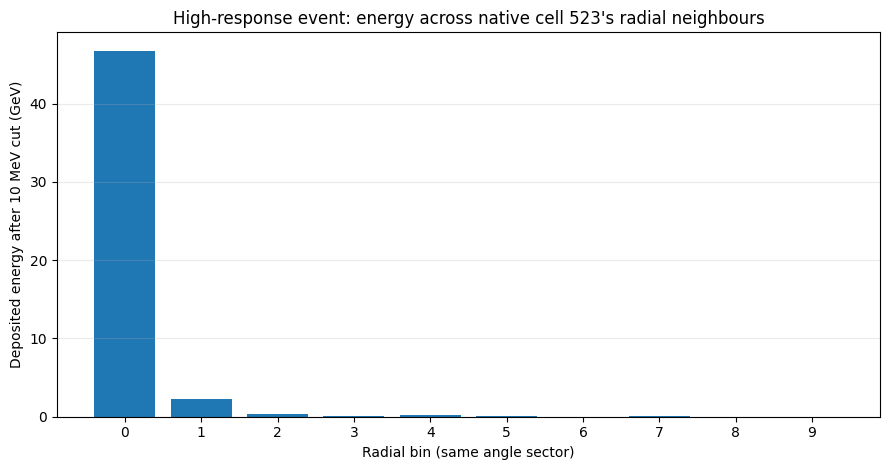

Cell 523 deposit: 46.757999 GeV
Cell 523 fraction of shower: 89.28%
Top 3 cells fraction: 94.33%
Top 5 cells fraction: 95.41%


In [ ]:
high = TARGET_NATIVE["high_response_cell523"]
high_spec = TARGETS["high_response_cell523"]
high_energy = high_spec["energy"]
high_incident = float(DATA[high_spec["seed"]][high_energy]["generator_run0"]["energy"][high_spec["row"]])
high_metrics = shower_metrics(high, high_incident)

print("High-response event:", high_spec["expected_event_id"])
print("Metrics:")
display(pd.DataFrame([high_metrics]).round(6))

high_top = top_cell_table(high, 20)
print("Top 20 native-cell deposits:")
display(high_top.round(6))
high_top.to_csv(OUTPUT_DIR / "high_response_top_cells.csv", index=False)

# Layer-by-layer energy profile.
high_layers = layer_energy_table(high)
print("Layer energies and fractions:")
display(high_layers.round(6))
high_layers.to_csv(OUTPUT_DIR / "high_response_layer_profile.csv", index=False)

# Check the final active layer's radial cells; cell 523 is its first radial bin.
cell523_info = cell_map.loc[cell_map.native_index == 523].iloc[0]
layer14_start, layer14_stop = LAYER_SLICES[int(cell523_info.layer_id)]
layer14_cells = cell_map[
    (cell_map.layer_id == int(cell523_info.layer_id)) &
    (cell_map.angle_index == int(cell523_info.angle_index))
].copy()
layer14_cells["event_energy_GeV"] = apply_analysis_cut(high)[
    layer14_cells.native_index.to_numpy(dtype=int)
]
print("Cell 523 and radial neighbours in the same angle sector:")
display(layer14_cells[[
    "native_index", "layer_id", "angle_index", "radial_bin",
    "r_low_XML", "r_high_XML", "event_energy_GeV"
]].round(6))
layer14_cells.to_csv(OUTPUT_DIR / "high_response_cell523_radial_neighbours.csv", index=False)

# Plot radial bins in the layer containing cell 523.
plt.figure(figsize=(9, 4.8))
plt.bar(
    layer14_cells["radial_bin"].astype(str),
    layer14_cells["event_energy_GeV"]
)
plt.xlabel("Radial bin (same angle sector)")
plt.ylabel("Deposited energy after 10 MeV cut (GeV)")
plt.title("High-response event: energy across native cell 523's radial neighbours")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "high_response_cell523_neighbours.png", dpi=160)
plt.show()

# Contribution of cell 523 and top cells to the event total.
cell523_energy = float(apply_analysis_cut(high)[523])
print(f"Cell 523 deposit: {cell523_energy:.6f} GeV")
print(f"Cell 523 fraction of shower: {cell523_energy/high_metrics['deposited_GeV']:.2%}")
print(f"Top 3 cells fraction: {high_top.head(3)['energy_GeV'].sum()/high_metrics['deposited_GeV']:.2%}")
print(f"Top 5 cells fraction: {high_top.head(5)['energy_GeV'].sum()/high_metrics['deposited_GeV']:.2%}")

### A2. Does cell 523 repeatedly receive large deposits?

We count deposits at the **same physical native cell** in the reference, generator and scale-only samples. The thresholds below (0.1, 1, 5, 10, 20, 40 GeV) are diagnostic thresholds, not additional detector cuts.

,energy_GeV,method,native_cell,diagnostic_threshold_GeV,n_showers,n_above_threshold,frequency,maximum_cell_deposit_GeV
0,8.192,reference,523,0.1,300,3,0.010000,0.245128
1,8.192,reference,523,1.0,300,0,0.000000,0.245128
2,8.192,reference,523,5.0,300,0,0.000000,0.245128
3,8.192,reference,523,10.0,300,0,0.000000,0.245128
4,8.192,reference,523,20.0,300,0,0.000000,0.245128
5,8.192,reference,523,40.0,300,0,0.000000,0.245128
6,8.192,generator_pooled,523,0.1,1800,10,0.005556,3.595040
7,8.192,generator_pooled,523,1.0,1800,3,0.001667,3.595040
8,8.192,generator_pooled,523,5.0,1800,0,0.000000,3.595040
9,8.192,generator_pooled,523,10.0,1800,0,0.000000,3.595040


,sample,n,mean_GeV,median_GeV,q95_GeV,q99_GeV,maximum_GeV
0,Reference,300,0.144273,0.0,0.179452,3.424636,20.411501
1,Generator pooled,1800,0.149346,0.0,0.279261,2.681995,46.757999
2,Scale-only,300,0.166755,0.0,0.396721,3.883180,18.021801


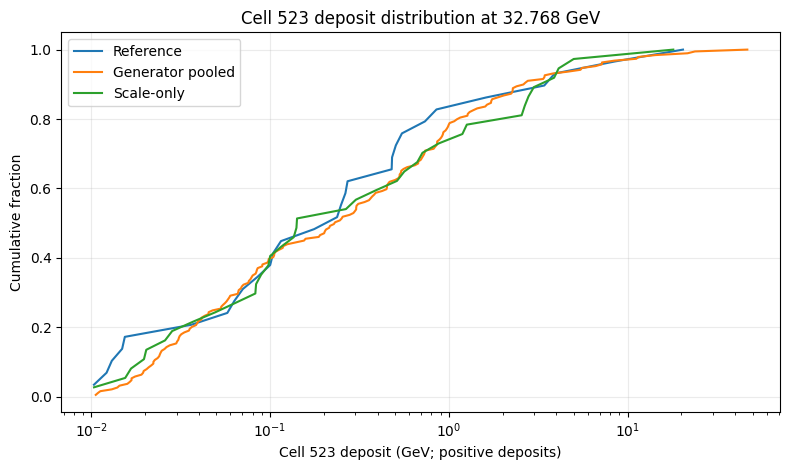

In [ ]:
CELL_OF_INTEREST = 523
thresholds = (0.1, 1.0, 5.0, 10.0, 20.0, 40.0)
recurrence_rows = []

for energy in ENERGIES:
    # Fixed reference and scale-only samples are the same across the runs.
    ref = DATA[base_seed][energy]["reference"]["native"]
    scale = DATA[base_seed][energy]["scale_only"]["native"]
    gen = np.concatenate([
        DATA[s][energy]["generator_run0"]["native"] for s in EXPECTED_SEEDS
    ] + [
        DATA[s][energy]["generator_run1"]["native"] for s in EXPECTED_SEEDS
    ], axis=0)

    for method, arr in [("reference", ref), ("generator_pooled", gen), ("scale_only", scale)]:
        vals = apply_analysis_cut(arr)[:, CELL_OF_INTEREST]
        for threshold in thresholds:
            recurrence_rows.append({
                "energy_GeV": energy,
                "method": method,
                "native_cell": CELL_OF_INTEREST,
                "diagnostic_threshold_GeV": threshold,
                "n_showers": len(vals),
                "n_above_threshold": int(np.sum(vals >= threshold)),
                "frequency": float(np.mean(vals >= threshold)),
                "maximum_cell_deposit_GeV": float(np.max(vals)),
            })

cell523_recurrence = pd.DataFrame(recurrence_rows)
display(cell523_recurrence.round(6))
cell523_recurrence.to_csv(OUTPUT_DIR / "cell523_recurrence.csv", index=False)

# Compare the full cell-523 deposit distribution at 32.768 GeV.
E = 32.768
cell_samples = {
    "Reference": apply_analysis_cut(DATA[base_seed][E]["reference"]["native"])[:, CELL_OF_INTEREST],
    "Generator pooled": np.concatenate([
        apply_analysis_cut(DATA[s][E][f"generator_run{r}"]["native"])[:, CELL_OF_INTEREST]
        for s in EXPECTED_SEEDS for r in (0,1)
    ]),
    "Scale-only": apply_analysis_cut(DATA[base_seed][E]["scale_only"]["native"])[:, CELL_OF_INTEREST],
}
cell_stats = []
for label, values in cell_samples.items():
    cell_stats.append({
        "sample": label, "n": len(values),
        "mean_GeV": np.mean(values), "median_GeV": np.median(values),
        "q95_GeV": np.quantile(values, .95),
        "q99_GeV": np.quantile(values, .99), "maximum_GeV": np.max(values)
    })
display(pd.DataFrame(cell_stats).round(6))

plt.figure(figsize=(8, 4.8))
for label, values in cell_samples.items():
    positive = np.sort(values[values > 0])
    if len(positive):
        y = np.arange(1, len(positive)+1) / len(positive)
        plt.plot(positive, y, label=label)
plt.xscale("log")
plt.xlabel("Cell 523 deposit (GeV; positive deposits)")
plt.ylabel("Cumulative fraction")
plt.title("Cell 523 deposit distribution at 32.768 GeV")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cell523_deposit_ecdf_32p768.png", dpi=160)
plt.show()

## 8. Investigation B — Very low-response event (0.00714)

This is the 65.536 GeV generated pion with only about 0.468 GeV deposited after the 10 MeV cut. We check whether it is empty (it is not), how many native cells remain active, which layers contain its energy and whether the energy is concentrated in one cell or distributed sparsely.

Low-response event: gen:pion:65.536GeV:0:5


,deposited_GeV,response,nhits,occupancy,depth_layer,r_mean_XML,r_rms_XML,r_sigma_XML
0,0.467939,0.00714,10,0.018762,2.113683,8.633487,22.438221,20.710786


Largest active cell deposits:


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_GeV,fraction_of_shower,rank
0,158,2,2,5,0,0.0,5.0,2.5,0.236817,0.506085,1
1,208,3,3,0,0,0.0,50.0,25.0,0.040520,0.086592,2
2,58,1,1,5,0,0.0,1.0,0.5,0.037304,0.079720,3
3,148,2,2,4,0,0.0,5.0,2.5,0.036889,0.078834,4
4,476,5,13,7,1,10.0,20.0,15.0,0.027690,0.059175,5
5,0,0,0,0,0,0.0,5.0,2.5,0.024049,0.051394,6
6,118,2,2,1,0,0.0,5.0,2.5,0.022224,0.047493,7
7,68,1,1,6,0,0.0,1.0,0.5,0.015534,0.033196,8
8,324,4,12,7,6,100.0,130.0,115.0,0.015271,0.032634,9
9,168,2,2,6,0,0.0,5.0,2.5,0.011641,0.024878,10


Layer-by-layer energy:


,layer_ordinal,layer_id,energy_GeV,fraction
0,0,0,0.024049,0.051394
1,1,1,0.052838,0.112916
2,2,2,0.307571,0.657289
3,3,3,0.040520,0.086592
4,4,12,0.015271,0.032634
5,5,13,0.027690,0.059175
6,6,14,0.000000,0.000000


Active native cells: 10 of 533
Maximum cell fraction: 50.61%
Selected event versus reference distribution:


,sample,response,occupancy,nhits,depth_layer,r_rms_XML
0,Selected low-response event,0.007140,0.018762,10.00,2.113683,22.438221
1,Reference q01,0.570693,0.253265,134.99,1.835379,58.625409
2,Reference median,0.814384,0.450281,240.00,3.768685,170.718758
3,Reference q99,1.052277,0.647336,345.03,5.177343,304.362760


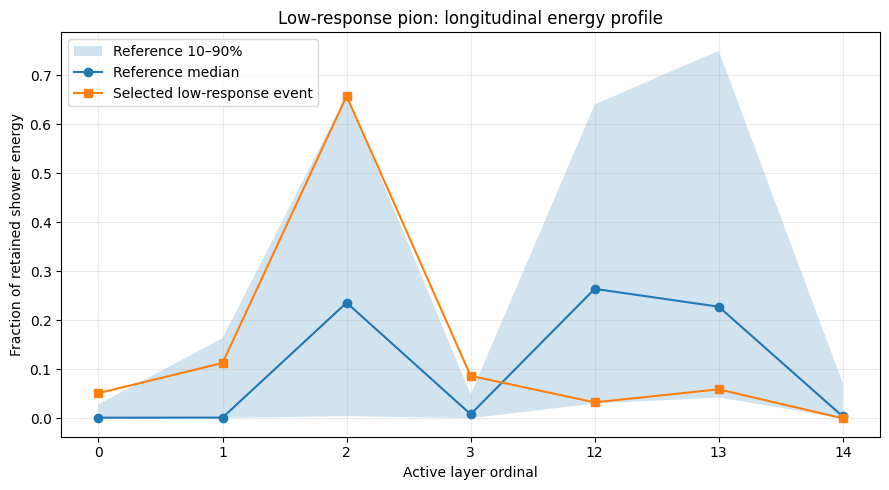

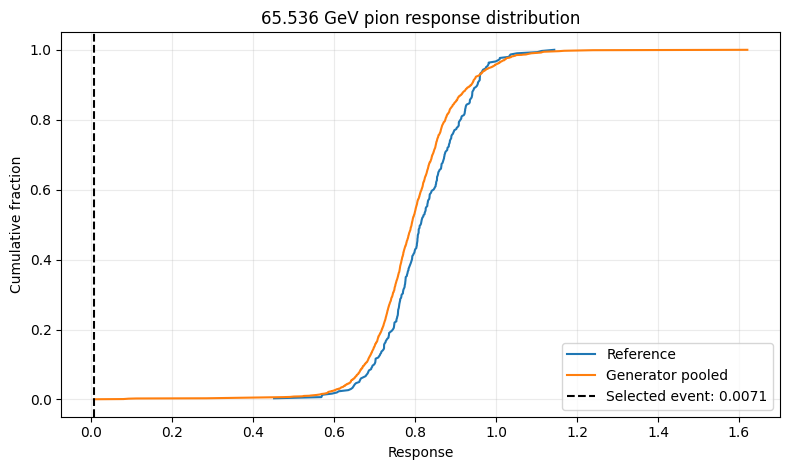

In [ ]:
low = TARGET_NATIVE["very_low_response"]
low_spec = TARGETS["very_low_response"]
low_energy = low_spec["energy"]
low_incident = float(DATA[low_spec["seed"]][low_energy]["generator_run0"]["energy"][low_spec["row"]])
low_kept = apply_analysis_cut(low)
low_metrics = shower_metrics(low, low_incident)

print("Low-response event:", low_spec["expected_event_id"])
display(pd.DataFrame([low_metrics]).round(8))

low_top = top_cell_table(low, 20)
print("Largest active cell deposits:")
display(low_top.round(6))
low_top.to_csv(OUTPUT_DIR / "low_response_top_cells.csv", index=False)

low_layers = layer_energy_table(low)
print("Layer-by-layer energy:")
display(low_layers.round(8))
low_layers.to_csv(OUTPUT_DIR / "low_response_layer_profile.csv", index=False)

print("Active native cells:", low_metrics["nhits"], "of", EXPECTED_NATIVE_CELLS)
print("Maximum cell fraction:",
      f"{low_top.iloc[0].energy_GeV/low_metrics['deposited_GeV']:.2%}")

# Compare this event's response and occupancy with fixed reference distributions.
ref_low = DATA[base_seed][65.536]["reference"]["native"]
ref_metrics_low = metric_distribution(ref_low, 65.536)
low_comparison = pd.DataFrame([
    {"sample": "Selected low-response event",
     "response": low_metrics["response"],
     "occupancy": low_metrics["occupancy"],
     "nhits": low_metrics["nhits"],
     "depth_layer": low_metrics["depth_layer"],
     "r_rms_XML": low_metrics["r_rms_XML"]},
    {"sample": "Reference q01", "response": ref_metrics_low.response.quantile(.01),
     "occupancy": ref_metrics_low.occupancy.quantile(.01),
     "nhits": ref_metrics_low.nhits.quantile(.01),
     "depth_layer": ref_metrics_low.depth_layer.quantile(.01),
     "r_rms_XML": ref_metrics_low.r_rms_XML.quantile(.01)},
    {"sample": "Reference median", "response": ref_metrics_low.response.median(),
     "occupancy": ref_metrics_low.occupancy.median(),
     "nhits": ref_metrics_low.nhits.median(),
     "depth_layer": ref_metrics_low.depth_layer.median(),
     "r_rms_XML": ref_metrics_low.r_rms_XML.median()},
    {"sample": "Reference q99", "response": ref_metrics_low.response.quantile(.99),
     "occupancy": ref_metrics_low.occupancy.quantile(.99),
     "nhits": ref_metrics_low.nhits.quantile(.99),
     "depth_layer": ref_metrics_low.depth_layer.quantile(.99),
     "r_rms_XML": ref_metrics_low.r_rms_XML.quantile(.99)},
])
print("Selected event versus reference distribution:")
display(low_comparison.round(6))
low_comparison.to_csv(OUTPUT_DIR / "low_response_vs_reference.csv", index=False)

# Plot layer-fraction profile of candidate against reference median and 10-90% band.
ref_layer_fraction = np.vstack([
    layer_profile(row) for row in ref_low
])
lo_q, med_q, hi_q = np.quantile(ref_layer_fraction, [0.10, 0.50, 0.90], axis=0)

plt.figure(figsize=(9, 5))
ord = layer_map.layer_ordinal.to_numpy()
plt.fill_between(ord, lo_q, hi_q, alpha=0.2, label="Reference 10–90%")
plt.plot(ord, med_q, marker="o", label="Reference median")
plt.plot(ord, layer_profile(low), marker="s", label="Selected low-response event")
plt.xlabel("Active layer ordinal")
plt.ylabel("Fraction of retained shower energy")
plt.title("Low-response pion: longitudinal energy profile")
plt.xticks(ord, [str(x) for x in layer_map.layer_id])
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "low_response_layer_profile_vs_reference.png", dpi=160)
plt.show()

# Response ECDF for full sample and mark the selected event.
ref_response = ref_metrics_low.response.to_numpy()
gen_low = np.concatenate([
    DATA[s][65.536][f"generator_run{r}"]["native"]
    for s in EXPECTED_SEEDS for r in (0,1)
], axis=0)
gen_low_metrics = metric_distribution(gen_low, 65.536)

plt.figure(figsize=(8, 4.8))
for label, vals in [("Reference", ref_response),
                    ("Generator pooled", gen_low_metrics.response.to_numpy())]:
    x = np.sort(vals)
    y = np.arange(1, len(x)+1)/len(x)
    plt.plot(x, y, label=label)
plt.axvline(low_metrics["response"], color="black", linestyle="--",
            label=f"Selected event: {low_metrics['response']:.4f}")
plt.xlabel("Response")
plt.ylabel("Cumulative fraction")
plt.title("65.536 GeV pion response distribution")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "low_response_event_response_ecdf.png", dpi=160)
plt.show()

## 9. Investigation C — Extreme radial-RMS event (996.55 XML units)

This is the 8.192 GeV generated pion from seed `20260110`, generation repeat 1, row 151. We recompute radial mean, RMS and radial standard deviation from the XML radial-bin centres. We then quantify how much each cell contributes to the radial second moment. This shows whether the large RMS is broadly distributed or dominated by one far-out cell.

Extreme radial event: gen:pion:8.192GeV:1:151


,deposited_GeV,response,nhits,occupancy,depth_layer,r_mean_XML,r_rms_XML,r_sigma_XML
0,2.939099,0.358777,28,0.052533,2.997057,761.974408,996.545564,642.260121


Top cells contributing to radial RMS:


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_GeV,r2_moment_contribution,fraction_of_r2_moment
257,257,4,12,2,14,1000.0,2000.0,1500.0,1.246666,2.804999e+06,0.961002
300,300,4,12,5,12,350.0,400.0,375.0,0.202272,2.844452e+04,0.009745
286,286,4,12,4,13,400.0,1000.0,700.0,0.028761,1.409299e+04,0.004828
207,207,2,2,9,9,300.0,400.0,350.0,0.080726,9.888905e+03,0.003388
156,156,2,2,4,8,200.0,300.0,250.0,0.152986,9.561611e+03,0.003276
346,346,4,12,8,13,400.0,1000.0,700.0,0.018266,8.950346e+03,0.003066
256,256,4,12,2,13,400.0,1000.0,700.0,0.014022,6.870887e+03,0.002354
146,146,2,2,3,8,200.0,300.0,250.0,0.108724,6.795234e+03,0.002328
211,211,3,3,0,3,200.0,400.0,300.0,0.068380,6.154186e+03,0.002108
155,155,2,2,4,7,130.0,200.0,165.0,0.166474,4.532242e+03,0.001553


Diagnostic sensitivity (do not modify the primary sample):


,case,removed_cells,deposited_GeV,response,r_rms_XML
0,Original shower,0,2.939099,0.358777,996.545564
1,Diagnostic only: remove cell 257,1,1.692433,0.206596,259.340939


Dominant cell details:


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_GeV,r2_moment_fraction
257,257,4,12,2,14,1000.0,2000.0,1500.0,1.246666,0.961002


Radial-band energy profile:


,radial_band_XML,r_low,r_high,energy_GeV,fraction
0,0-10,0,10,0.000000,0.000000
1,10-30,10,30,0.045451,0.015464
2,30-50,30,50,0.128791,0.043820
3,50-100,50,100,0.058106,0.019770
4,100-200,100,200,0.683370,0.232510
5,200-400,200,400,0.715665,0.243498
6,400-600,400,600,0.000000,0.000000
7,600-1000,600,1000,0.061049,0.020771
8,1000-2000,1000,2000,1.246666,0.424166


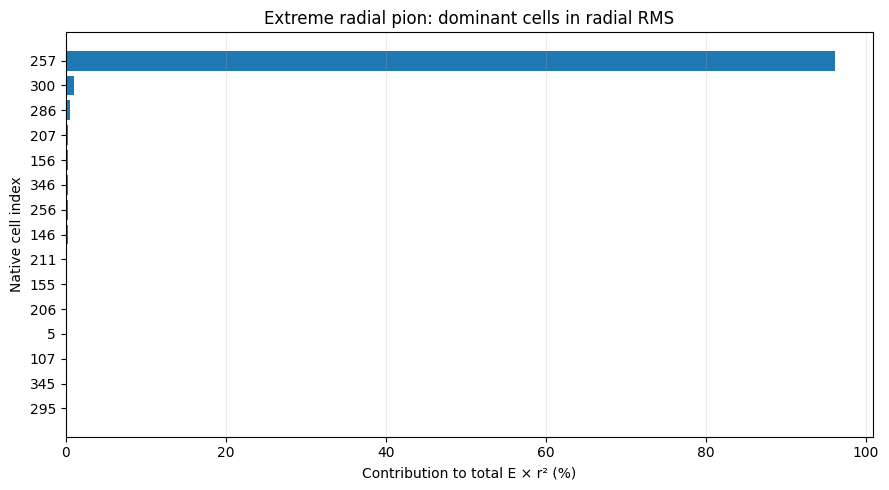

In [ ]:
radial = TARGET_NATIVE["extreme_radial_rms"]
radial_spec = TARGETS["extreme_radial_rms"]
radial_incident = float(DATA[radial_spec["seed"]][8.192]["generator_run1"]["energy"][radial_spec["row"]])
radial_kept = apply_analysis_cut(radial)
radial_total = float(radial_kept.sum())
radial_metrics = shower_metrics(radial, radial_incident)

# Per-cell contribution to the radial second-moment numerator E*r^2.
r2_contribution = radial_kept * CELL_RADII**2
r2_total = float(r2_contribution.sum())
radial_detail = cell_map.copy()
radial_detail["energy_GeV"] = radial_kept
radial_detail["r2_moment_contribution"] = r2_contribution
radial_detail["fraction_of_r2_moment"] = (
    r2_contribution / r2_total if r2_total > 0 else 0.0
)
radial_detail = radial_detail[radial_detail.energy_GeV > 0].sort_values(
    "r2_moment_contribution", ascending=False
)

print("Extreme radial event:", radial_spec["expected_event_id"])
display(pd.DataFrame([radial_metrics]).round(6))
print("Top cells contributing to radial RMS:")
display(radial_detail.head(20).round(6))
radial_detail.to_csv(OUTPUT_DIR / "extreme_radial_cell_contributions.csv", index=False)

# Sensitivity only: remove the single cell with the largest E*r^2 contribution.
dominant_cell = int(radial_detail.iloc[0].native_index)
without_dominant = radial_kept.copy()
without_dominant[dominant_cell] = 0.0
remaining_total = float(without_dominant.sum())
remaining_rms = float(np.sqrt(
    np.sum(without_dominant * CELL_RADII**2) / remaining_total
)) if remaining_total > 0 else np.nan

sensitivity = pd.DataFrame([
    {
        "case": "Original shower",
        "removed_cells": 0,
        "deposited_GeV": radial_total,
        "response": radial_total / radial_incident,
        "r_rms_XML": radial_metrics["r_rms_XML"],
    },
    {
        "case": f"Diagnostic only: remove cell {dominant_cell}",
        "removed_cells": 1,
        "deposited_GeV": remaining_total,
        "response": remaining_total / radial_incident,
        "r_rms_XML": remaining_rms,
    }
])
print("Diagnostic sensitivity (do not modify the primary sample):")
display(sensitivity.round(6))
sensitivity.to_csv(OUTPUT_DIR / "extreme_radial_single_cell_sensitivity.csv", index=False)

print("Dominant cell details:")
display(cell_map.loc[cell_map.native_index == dominant_cell].assign(
    energy_GeV=radial_kept[dominant_cell],
    r2_moment_fraction=r2_contribution[dominant_cell]/r2_total
))

# Candidate's radial-band energy profile.
candidate_radial_profile = radial_band_profile(radial)
candidate_radial_profile.to_csv(
    OUTPUT_DIR / "extreme_radial_candidate_radial_bands.csv", index=False
)
print("Radial-band energy profile:")
display(candidate_radial_profile.round(6))

# Plot per-cell contribution to the radial second moment.
plot_top = radial_detail.head(15).sort_values("fraction_of_r2_moment")
plt.figure(figsize=(9, 5))
plt.barh(plot_top.native_index.astype(str), 100*plot_top.fraction_of_r2_moment)
plt.xlabel("Contribution to total E × r² (%)")
plt.ylabel("Native cell index")
plt.title("Extreme radial pion: dominant cells in radial RMS")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "extreme_radial_r2_contributions.png", dpi=160)
plt.show()

### C2. Compare the extreme shower with reference and generated populations

We compare radial RMS distributions using the same XML radial-bin centres and the same 10 MeV cutoff. The selected event is shown against the reference distribution and the pooled three-seed generator sample.

Radial RMS population comparison at 8.192 GeV:


,sample,n,median,q95,q99,maximum
0,Reference,300,221.610528,464.915213,575.202403,707.334378
1,Generator pooled,1800,215.433310,471.683216,604.194480,996.545564
2,Scale-only,300,166.824445,315.253339,379.954749,491.716846


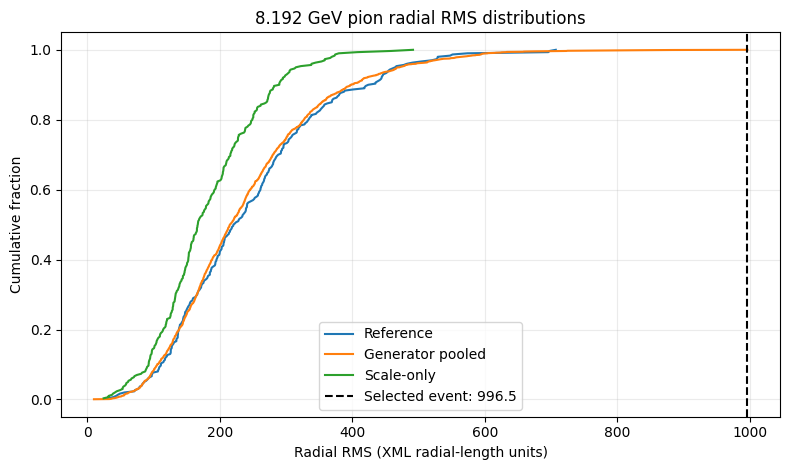

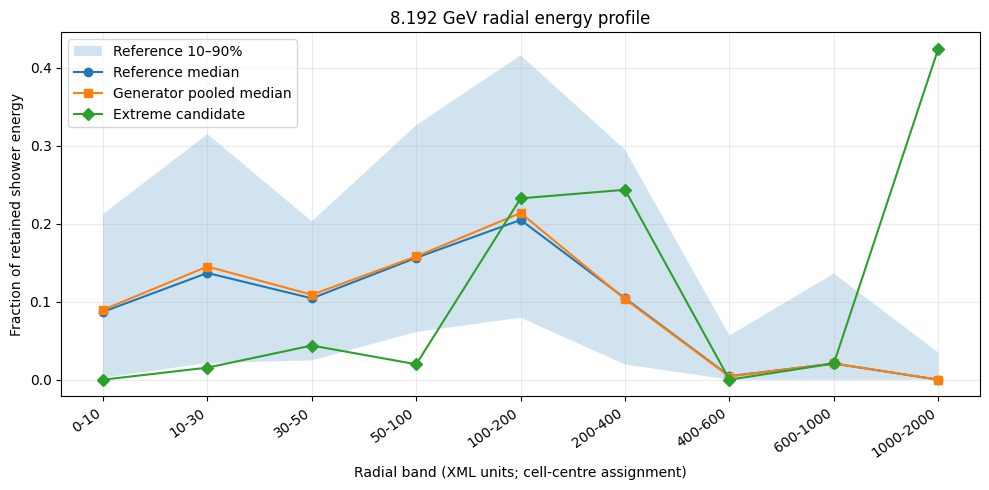

In [ ]:
def radial_metric_array(native_2d):
    kept = apply_analysis_cut(native_2d)
    totals = kept.sum(axis=1)
    numer = np.sum(kept * CELL_RADII[None, :]**2, axis=1)
    return np.sqrt(np.divide(numer, totals, out=np.full_like(totals, np.nan), where=totals>0))

ref_radial = DATA[base_seed][8.192]["reference"]["native"]
ref_rms = radial_metric_array(ref_radial)
gen_radial = np.concatenate([
    DATA[s][8.192][f"generator_run{r}"]["native"]
    for s in EXPECTED_SEEDS for r in (0,1)
], axis=0)
gen_rms = radial_metric_array(gen_radial)
scale_radial = DATA[base_seed][8.192]["scale_only"]["native"]
scale_rms = radial_metric_array(scale_radial)

radial_pop_summary = pd.DataFrame([
    {"sample": label, "n": len(v), "median": np.nanmedian(v),
     "q95": np.nanquantile(v,.95), "q99": np.nanquantile(v,.99),
     "maximum": np.nanmax(v)}
    for label, v in [("Reference", ref_rms),
                     ("Generator pooled", gen_rms),
                     ("Scale-only", scale_rms)]
])
print("Radial RMS population comparison at 8.192 GeV:")
display(radial_pop_summary.round(6))
radial_pop_summary.to_csv(OUTPUT_DIR / "radial_rms_population_comparison.csv", index=False)

plt.figure(figsize=(8, 4.8))
for label, vals in [("Reference", ref_rms),
                    ("Generator pooled", gen_rms),
                    ("Scale-only", scale_rms)]:
    x = np.sort(vals[np.isfinite(vals)])
    y = np.arange(1, len(x)+1)/len(x)
    plt.plot(x, y, label=label)
plt.axvline(radial_metrics["r_rms_XML"], color="black", linestyle="--",
            label=f"Selected event: {radial_metrics['r_rms_XML']:.1f}")
plt.xlabel("Radial RMS (XML radial-length units)")
plt.ylabel("Cumulative fraction")
plt.title("8.192 GeV pion radial RMS distributions")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "extreme_radial_rms_ecdf.png", dpi=160)
plt.show()

# Compare the candidate's radial-band profile with reference median and 10-90% range.
ref_band_profiles = np.vstack([
    radial_band_profile(row)["fraction"].to_numpy()
    for row in ref_radial
])
gen_band_profiles = np.vstack([
    radial_band_profile(row)["fraction"].to_numpy()
    for row in gen_radial
])
ref_lo, ref_med, ref_hi = np.quantile(ref_band_profiles, [0.10,.50,.90], axis=0)
gen_med = np.quantile(gen_band_profiles, .50, axis=0)

bands = candidate_radial_profile.radial_band_XML.tolist()
x = np.arange(len(bands))
plt.figure(figsize=(10, 5))
plt.fill_between(x, ref_lo, ref_hi, alpha=.2, label="Reference 10–90%")
plt.plot(x, ref_med, marker="o", label="Reference median")
plt.plot(x, gen_med, marker="s", label="Generator pooled median")
plt.plot(x, candidate_radial_profile.fraction, marker="D", label="Extreme candidate")
plt.xticks(x, bands, rotation=35, ha="right")
plt.ylabel("Fraction of retained shower energy")
plt.xlabel("Radial band (XML units; cell-centre assignment)")
plt.title("8.192 GeV radial energy profile")
plt.grid(alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "extreme_radial_band_profile.png", dpi=160)
plt.show()

## 10. Cross-checks and concise interpretation

This final section summarises what the three targeted investigations establish. It does not label any event as physically impossible. The reference sample is finite, and reference/checkpoint independence remains unverified.

In [ ]:
# Build a compact, machine-readable findings table.
high_top5_fraction = float(high_top.head(5).energy_GeV.sum() / high_metrics["deposited_GeV"])
cell523_fraction = float(apply_analysis_cut(high)[523] / high_metrics["deposited_GeV"])
low_top1_fraction = float(low_top.iloc[0].energy_GeV / low_metrics["deposited_GeV"])
radial_topcell_fraction_r2 = float(radial_detail.iloc[0].fraction_of_r2_moment)

findings = pd.DataFrame([
    {
        "investigation": "high_response_32p768",
        "event_id": high_spec["expected_event_id"],
        "key_result": f"response={high_metrics['response']:.6f}; cell523={cell523_energy:.6f} GeV; cell523 fraction={cell523_fraction:.3%}; top5 fraction={high_top5_fraction:.3%}",
        "interpretation": "Extreme localized deposit in native cell 523 (layer 14, angle 0, radial bin 0; 0–50 XML units). This is a generated-array observation; physical cause not determined here."
    },
    {
        "investigation": "low_response_65p536",
        "event_id": low_spec["expected_event_id"],
        "key_result": f"response={low_metrics['response']:.6f}; deposited={low_metrics['deposited_GeV']:.6f} GeV; hits={low_metrics['nhits']}; leading-cell fraction={low_top1_fraction:.3%}",
        "interpretation": "Very low but non-empty shower. Inspect layer distribution and top cells; this saved-array audit does not determine why the model generated it."
    },
    {
        "investigation": "extreme_radial_8p192",
        "event_id": radial_spec["expected_event_id"],
        "key_result": f"r_rms={radial_metrics['r_rms_XML']:.3f}; dominant cell={dominant_cell}; its r2-moment fraction={radial_topcell_fraction_r2:.3%}; RMS after diagnostic removal={remaining_rms:.3f}",
        "interpretation": "Radial RMS is dominated by one far-out cell. Cell removal is a sensitivity test only; keep the original shower in primary comparisons."
    }
])

display(findings)
findings.to_csv(OUTPUT_DIR / "pion_final_three_investigations_findings.csv", index=False)

print("\nRun compatibility:", "PASS" if compatibility[must_match].all().all() else "FAIL")
print("Native geometry cell count:", len(cell_map))
print("Reference unseen by checkpoint:", bool(compatibility.reference_unseen_by_checkpoint.all()))
print("\nInterpretation limits:")
print("- These are three selected candidate events, not proof of a population-wide defect.")
print("- The 0.1/1/5/10/20/40 GeV cell thresholds are diagnostic thresholds, not detector analysis cuts.")
print("- The 10 MeV analysis cutoff was applied consistently to reference, generator and scale-only arrays.")
print("- The reference contains 300 showers per energy; rare-tail rates have substantial sampling uncertainty.")
print("- Checkpoint/reference training and selection independence is NOT established by these ZIPs.")

,investigation,event_id,key_result,interpretation
0,high_response_32p768,gen:pion:32.768GeV:0:106,response=1.598272; cell523=46.757999 GeV; cell...,Extreme localized deposit in native cell 523 (...
1,low_response_65p536,gen:pion:65.536GeV:0:5,response=0.007140; deposited=0.467939 GeV; hit...,Very low but non-empty shower. Inspect layer d...
2,extreme_radial_8p192,gen:pion:8.192GeV:1:151,r_rms=996.546; dominant cell=257; its r2-momen...,Radial RMS is dominated by one far-out cell. C...



Run compatibility: PASS
Native geometry cell count: 533
Reference unseen by checkpoint: False

Interpretation limits:
- These are three selected candidate events, not proof of a population-wide defect.
- The 0.1/1/5/10/20/40 GeV cell thresholds are diagnostic thresholds, not detector analysis cuts.
- The 10 MeV analysis cutoff was applied consistently to reference, generator and scale-only arrays.
- The reference contains 300 showers per energy; rare-tail rates have substantial sampling uncertainty.
- Checkpoint/reference training and selection independence is NOT established by these ZIPs.


## 11. Export all tables and figures

In [ ]:
import shutil

# Write a concise report alongside the detailed CSVs and figures.
report_text = f"""# Pion Final Three Investigations — Results

## Run consistency
- Generation seeds: {list(EXPECTED_SEEDS)}
- Same reference arrays/event IDs: verified
- Same scale-only arrays/event IDs: verified
- Same checkpoint, partition, donor hashes and cutoff: verified
- Reference unseen by checkpoint: {bool(compatibility.reference_unseen_by_checkpoint.all())}

## Candidate A — High response at 32.768 GeV
- Event: {high_spec['expected_event_id']}
- Deposited energy: {high_metrics['deposited_GeV']:.6f} GeV
- Response: {high_metrics['response']:.6f}
- Native cell 523: {cell523_energy:.6f} GeV ({cell523_fraction:.2%} of total)
- Top five cells: {high_top5_fraction:.2%} of total
- Cell 523 geometry: XML layer 14, angle 0, radial bin 0, 0–50 XML units

## Candidate B — Very low response at 65.536 GeV
- Event: {low_spec['expected_event_id']}
- Deposited energy: {low_metrics['deposited_GeV']:.6f} GeV
- Response: {low_metrics['response']:.6f}
- Active native cells: {low_metrics['nhits']} / {EXPECTED_NATIVE_CELLS}
- Largest cell: {low_top.iloc[0].native_index} with {low_top.iloc[0].energy_GeV:.6f} GeV

## Candidate C — Extreme radial RMS at 8.192 GeV
- Event: {radial_spec['expected_event_id']}
- Radial RMS: {radial_metrics['r_rms_XML']:.6f} XML units
- Dominant radial-moment cell: {dominant_cell}
- Fraction of E*r^2 moment from that cell: {radial_topcell_fraction_r2:.2%}
- RMS after diagnostic removal of that one cell: {remaining_rms:.6f} XML units

## Interpretation limits
- Cell removal is a diagnostic sensitivity test only; original showers remain in all primary comparisons.
- These candidate events do not by themselves establish a population-wide model defect.
- Reference/checkpoint training and selection independence remains unverified.
"""
(OUTPUT_DIR / "pion_final_three_investigations_report.md").write_text(report_text, encoding="utf-8")

zip_output = Path("/content/pion_final_three_investigations_results.zip")
if zip_output.exists():
    zip_output.unlink()

shutil.make_archive(
    str(zip_output.with_suffix("")),
    "zip",
    root_dir=OUTPUT_DIR
)

print("Results saved:", zip_output)
files.download(str(zip_output))

Results saved: /content/pion_final_three_investigations_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. What would count as a useful conclusion?

After running this notebook, retain the three original events in the fidelity sample and report:

- **Cell-523 event:** whether the 46.76 GeV deposit is concentrated in the first radial bin of XML layer 14 and how frequently the same cell receives large deposits in reference, generator and scale-only samples.
- **Low-response event:** its active-cell count, largest deposits, and layer-by-layer energy fractions. Distinguish a sparse shower from a shower whose energy is concentrated in a small number of cells.
- **Extreme-radial event:** the dominant cells in the radial second moment and how much the RMS changes when the dominant cell is excluded *for diagnosis only*.

Do not infer physical impossibility from a finite reference maximum. Do not remove anomalous events from the primary fidelity distributions. The next step after this notebook is a concise pion closeout report; these diagnostics do not require another generation run.